<a href="https://colab.research.google.com/github/hcarpenter30/IS4487_my_portfolio/blob/main/carpenter_henry_assignment_09_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
import pandas as pd
import numpy as np

# URL to the raw hotels.csv dataset on GitHub
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv'

# Import data into a dataframe
df = pd.read_csv(url)

# Display the first few rows
print("First 5 rows of the dataset:")
display(df.head())

# Show summary statistics for the dataframe
print("\nSummary Statistics:")
display(df.describe(include='all'))

First 5 rows of the dataset:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Summary Statistics:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. After the initial preview of the data, I see a few different things that stand out. About 25% of the bookings in the dataset were canceled, and for pricing, there seems to be a negative number which is definitely an outlier but it interesting to see. Also, the agent and company columns have a lot of null values which seems unusual.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 2.1 Choose 3-5 numeric features related to customer behavior
# We will choose:
# - lead_time (how far in advance they book)
# - stays_in_weekend_nights (weekend stay length)
# - stays_in_week_nights (weekday stay length)
# - adr (average daily rate/spend behavior)
selected_features = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adr']

# Create a copy of the dataframe with selected features
df_prep = df[selected_features].copy()

# 2.2 Perform basic data preparation - remove duplicates and handle outliers
# Remove duplicates
df_prep.drop_duplicates(inplace=True)

# Remove outliers (e.g., negative or extreme ADR, extremely high lead times)
df_prep = df_prep[(df_prep['adr'] >= 0) & (df_prep['adr'] < 1000)]
df_prep = df_prep[df_prep['lead_time'] <= 365]  # bookings less than a year in advance

# 2.3 Drop missing values if needed
df_prep.dropna(inplace=True)

# 2.4 Standardize using StandardScaler for any large values (over 100)
# 'lead_time' and 'adr' frequently exceed 100, so we will scale them
scaler = StandardScaler()
df_prep[['lead_time', 'adr']] = scaler.fit_transform(df_prep[['lead_time', 'adr']])

# Preview the prepared dataset
print(f"Prepared dataset shape: {df_prep.shape}")
display(df_prep.head())

Prepared dataset shape: (6377, 4)


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr
0,3.771994,0,0,-1.748337
2,-0.843642,0,1,-0.402881
3,-0.760973,0,1,-0.402881
4,-0.747195,0,2,0.009725
6,-0.940088,0,2,0.171180


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. The new features I selected were lead time, stays in either the weekend or weekdays, and average daily rate/spending behavior. I thought these new features would provide some interesting insight and allow me to better understand each variable with the different correlations they could have with each other.

2. Personally, I expect to find different patterns and segments around lead time and its impact on weekend stays. It would make sense that people would have a higher lead time if they stayed on the weekend, since vacations like that tend to be planned in advance. I also think that stays in week day nights will of course be higher than the stays in weekend nights.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

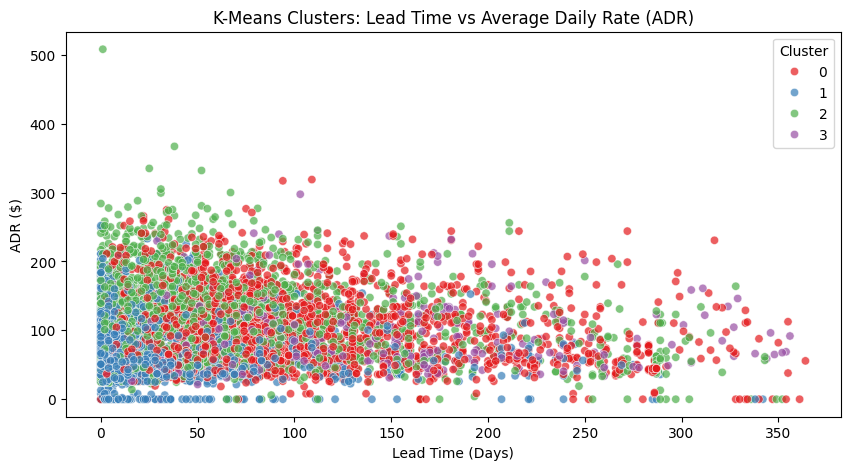

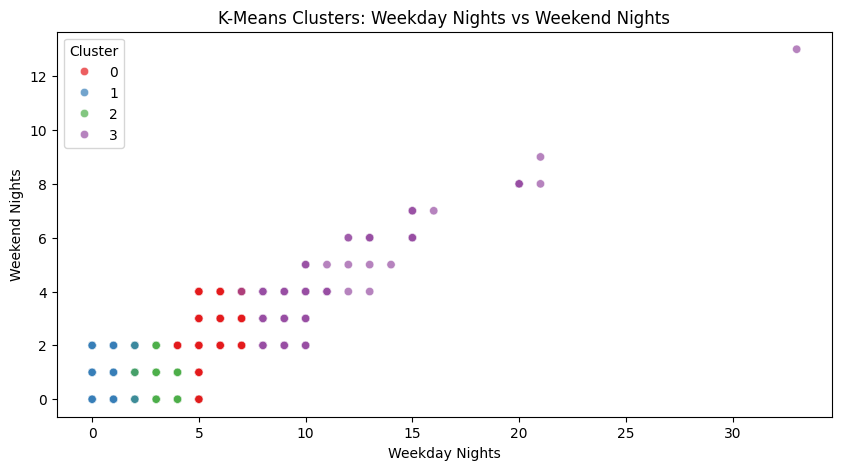

Cluster Averages (Original Scale):


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr
kmeans_cluster,,,,
0,101.469277,2.060456,5.196234,105.107398
1,25.232194,0.630579,1.084995,69.783229
2,69.322105,0.845789,3.001579,120.592932
3,128.875354,3.628895,9.810198,94.311870


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Fit KMeans model with k=4
k = 4
kmeans = KMeans(n_clusters=k, random_state=42)
df_prep['kmeans_cluster'] = kmeans.fit_predict(df_prep[selected_features])

# Create a copy of the original non-scaled values for easier business interpretation
# Aligning the rows to match the cleaned and deduplicated df_prep
df_original = df.loc[df_prep.index].copy()
df_original['kmeans_cluster'] = df_prep['kmeans_cluster']

# 1st Visualization: Lead Time vs ADR
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_original, x='lead_time', y='adr', hue='kmeans_cluster', palette='Set1', alpha=0.7)
plt.title('K-Means Clusters: Lead Time vs Average Daily Rate (ADR)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('ADR ($)')
plt.legend(title='Cluster')
plt.show()

# 2nd Visualization: Weekday Nights vs Weekend Nights
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_original, x='stays_in_week_nights', y='stays_in_weekend_nights', hue='kmeans_cluster', palette='Set1', alpha=0.7)
plt.title('K-Means Clusters: Weekday Nights vs Weekend Nights')
plt.xlabel('Weekday Nights')
plt.ylabel('Weekend Nights')
plt.legend(title='Cluster')
plt.show()

# Create a summary table showing original averages for each variable broken out by cluster
print("Cluster Averages (Original Scale):")
summary_kmeans = df_original.groupby('kmeans_cluster')[selected_features].mean()
display(summary_kmeans)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. For this step, I decided to chose 4 for k, in other words, creating 4 different clusters for examination. I decided on 4 because it made sense and felt like the perfect amount where I would be able to draw some strong conclusions about the dataset. 2 would have been too few, and a k of 8 would be too much and would lead to overfitting.

2. Cluster 0: Guests stay quite long, and they also plan ahead. Prominent variables are weekday nights, weekend nights, and high lead time.
Cluster 1: These guests are spontaneous travelers with a short lead time and they also stay for very short periods. The prominent variables are low lead time, short stays, and the lowest adr.
Cluster 2: Guests plan far in advance and pay high rates. Prominent variables are high adr and moderate stay length
Cluster 3: Guests are extremely early planners. Prominent variables are the highest lead time, highest nights stayed.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

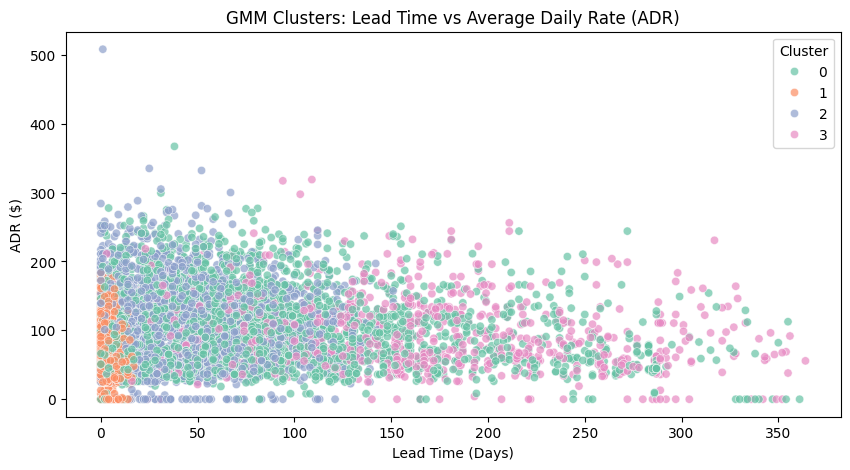

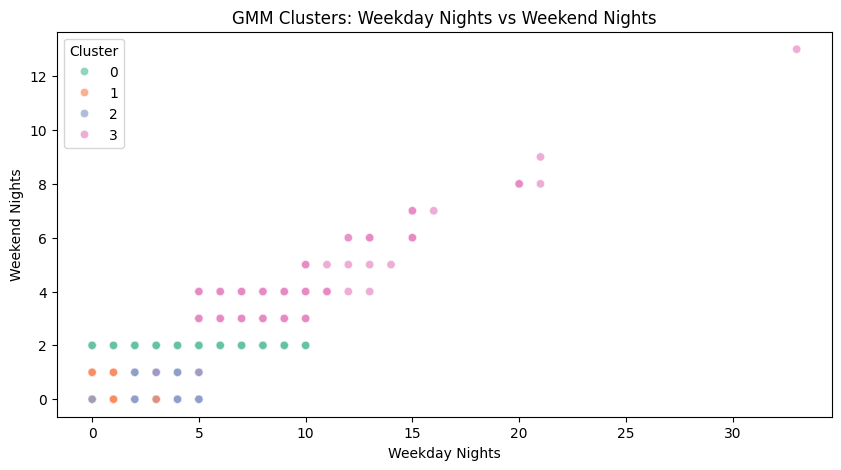

GMM Cluster Averages (Original Scale):


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr
gmm_cluster,,,,
0,85.775608,2.000000,4.186927,105.690375
1,4.056800,0.350400,1.212800,65.776000
2,47.018467,0.438165,2.666480,109.426603
3,157.406739,2.569194,6.198556,94.520313


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture

# 1. Fit Gaussian Mixture Model with 4 components
gmm = GaussianMixture(n_components=4, random_state=42)
gmm.fit(df_prep[selected_features])

# Predict probabilities (soft clustering)
probabilities = gmm.predict_proba(df_prep[selected_features])

# Assign hard label based on the highest probability
df_prep['gmm_cluster'] = probabilities.argmax(axis=1)

# Create a copy of the original non-scaled data mapped to the clean indices
df_original['gmm_cluster'] = df_prep['gmm_cluster']

# Add probability details to df_original if needed for analysis
for i in range(4):
    df_original[f'gmm_prob_cluster_{i}'] = probabilities[:, i]

# 2. 1st Visualization: Lead Time vs ADR
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_original, x='lead_time', y='adr', hue='gmm_cluster', palette='Set2', alpha=0.7)
plt.title('GMM Clusters: Lead Time vs Average Daily Rate (ADR)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('ADR ($)')
plt.legend(title='Cluster')
plt.show()

# 3. 2nd Visualization: Weekday Nights vs Weekend Nights
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_original, x='stays_in_week_nights', y='stays_in_weekend_nights', hue='gmm_cluster', palette='Set2', alpha=0.7)
plt.title('GMM Clusters: Weekday Nights vs Weekend Nights')
plt.xlabel('Weekday Nights')
plt.ylabel('Weekend Nights')
plt.legend(title='Cluster')
plt.show()

# 4. Summary table showing the averages for each variable, broken out by GMM cluster
print("GMM Cluster Averages (Original Scale):")
summary_gmm = df_original.groupby('gmm_cluster')[selected_features].mean()
display(summary_gmm)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. After using GMM to compare to KMeans clustering, there were a few differences. It seems like GMM is more sensitive to detecing changes in behavior and is better at identifying the ultra-spontaneous guests who have very short lead time. Overall, I think GMM is more sensitive and can pick up more information that KMeans cant.

2. I think two questions that GMM might help answer better are, "Which customers are on the fence between two segments?", and, "How do we handle overlapping behaviors?"


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [5]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

# Features used for clustering
X = df_prep[selected_features]

# --- 1. K-Means Metrics ---
# WCSS (Inertia in scikit-learn)
kmeans_wcss = kmeans.inertia_

# Silhouette Score
kmeans_silhouette = silhouette_score(X, df_prep['kmeans_cluster'])

# Davies-Bouldin Index
kmeans_db_index = davies_bouldin_score(X, df_prep['kmeans_cluster'])

# --- 2. GMM Metrics ---
# GMM doesn't have a direct WCSS metric like KMeans, but we can compute the sum of squared distances
# of each sample to its assigned cluster center (centroid)
gmm_centroids = []
for i in range(4):
    gmm_centroids.append(X[df_prep['gmm_cluster'] == i].mean(axis=0))
gmm_centroids = np.array(gmm_centroids)

gmm_wcss = 0
for i in range(4):
    cluster_points = X[df_prep['gmm_cluster'] == i]
    if len(cluster_points) > 0:
        gmm_wcss += np.sum((cluster_points - gmm_centroids[i]) ** 2).sum()

# Silhouette Score
gmm_silhouette = silhouette_score(X, df_prep['gmm_cluster'])

# Davies-Bouldin Index
gmm_db_index = davies_bouldin_score(X, df_prep['gmm_cluster'])

# Display Results
metrics_df = pd.DataFrame({
    'Metric': ['Within-Cluster Sum of Squares (WCSS)', 'Silhouette Score', 'Davies-Bouldin Index'],
    'K-Means': [kmeans_wcss, kmeans_silhouette, kmeans_db_index],
    'GMM': [gmm_wcss, gmm_silhouette, gmm_db_index]
})

display(metrics_df)

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


,Metric,K-Means,GMM
0,Within-Cluster Sum of Squares (WCSS),19690.460121,35906.208650
1,Silhouette Score,0.296157,0.102059
2,Davies-Bouldin Index,1.186611,2.049477


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. The KMeans model performed better on all of the metrics above. That model had a better WCSS, Silhouette Score, and Davies-Bouldin Index

5.3. Personally, I would recommend KMeans for a business analyst. I say this because it is a faster process and easier to complete than the GMM. Also, given the scores and comparision between the two models, KMeans, had the better scores. Overall, as an analyst, I would use KMeans as the primary method and GMM as a backup.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [6]:
import pandas as pd

# Map the K-Means cluster back to the original full dataframe for the aligned rows
df_original['total_of_special_requests'] = df.loc[df_prep.index, 'total_of_special_requests']

# Group by cluster and calculate mean characteristics
cluster_analysis = df_original.groupby('kmeans_cluster')[[
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adr',
    'total_of_special_requests'
]].mean()

# Sort the clusters by lead_time to make differences more clear and structured
cluster_analysis_sorted = cluster_analysis.sort_values(by='lead_time')

print("Characteristics of each K-Means Cluster (Sorted by Lead Time):")
display(cluster_analysis_sorted)

Characteristics of each K-Means Cluster (Sorted by Lead Time):


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
kmeans_cluster,,,,,
1,25.232194,0.630579,1.084995,69.783229,0.636277
2,69.322105,0.845789,3.001579,120.592932,0.830526
0,101.469277,2.060456,5.196234,105.107398,0.757681
3,128.875354,3.628895,9.810198,94.311870,0.716714


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Cluster 0: Standard planned stayers
Cluster 1: Spontaneous short-stayers
Cluster 2: Mid-lead, higher spenders
Cluster 3: Extreme long-stay vacationers

2. For cluster 0, launch early-bird booking campaigns to get them to secure their bookings early. For cluster 1, offer quick flash sales and last minute discounts to appeal to their last minute booking nature. For cluster 2, target them with upsell opportunities. For cluster 3, promote multi-day packages and free laundry services for their extened stays.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Personally, I thought the most challenging thing about unsupervised learning is the vast amount of possoibilities in terms of the outcome. It can be hard to predict what you might get from the data, and it can be a million different conclusions.

2. I would use clustering when I wanted to test my data and find out certain trends or things about the dataset, especially the values within. It would help me better understand certain groups within my data and find unique things that supervised learning models couldn't.

3. I would explain it as a way to better understand parts of the data and to uncover relationships in the dataset as well. Clustering can be beneficial for many different people in a business, especially when it comes to grouping data together to disect it.

4. This related to my customized learning outcomes because it showed me the importance of understanding and learning from your dataset. As a finance major, its important, not only that you test your data and come up with conclusions, but that you understand what is being spit out. In this case, its important to understand what each cluster represents and how exactly the differ from one another.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [7]:
!jupyter nbconvert --to html "carpenter_henry_assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook carpenter_henry_assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 1092894 bytes to carpenter_henry_assignment_09_clustering.html
